# Grover template matching: "Where is Waldo?" (toy version)

Reimplementation of the matching part of *Tezuka et al., "Grover search revisited; application to image pattern matching"* (arXiv:2108.10854).

**Idea in one paragraph.** Every window of a big image becomes one entry of a quantum database `|database> ~ sum_k |data(k)>|k>`. Applying `B†` (the inverse of the query-loading circuit) to the data register turns *"window k looks like the query"* into *"data register reads 0…0 at index k"*. Grover's amplitude amplification then boosts all the "reads 0…0" parts together. The oracle is just a phase flip on `|0…0>` of the data register, so it never needs to know the answer.

**Code layout.** Classes live in `grover_tm/*.py`; this notebook only runs and tests them.

| module | role |
|---|---|
| `encoders.py` | patch → vector (`NEQREncoder`, `AmplitudeNCCEncoder`) |
| `database.py` | sliding windows → database vector |
| `loaders.py` | vector → circuit (`ExactStatePrepLoader`; AAE would go here) |
| `matcher.py` | `U`, `G_o`, `G_d`, `G`, sampling, exact analysis |
| `scenes.py`, `visualization.py` | toy scenes and plots |

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from grover_tm import (SceneGenerator, WindowExtractor, WindowDatabase,
                       NEQREncoder, AmplitudeNCCEncoder,
                       GroverTemplateMatcher, MatchVisualizer)

np.set_printoptions(precision=3, suppress=True)

## 1. The scene
An 8×8 binary image with random noise, one exact 4×4 Waldo (red) and one *decoy* (orange) that is Waldo with 2 flipped pixels.

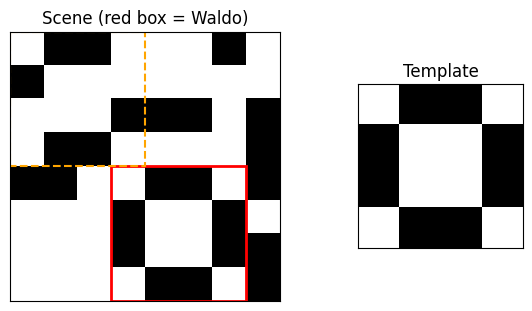

In [2]:
scene = SceneGenerator(scene_shape=(8, 8), noise_density=0.25, seed=7).make(
    waldo_position=(4, 3), decoys=(((0, 0), 2),))

fig, ax = plt.subplots(1, 2, figsize=(7, 3.5), gridspec_kw={"width_ratios": [2, 1]})
MatchVisualizer.show_scene(scene, ax[0])
MatchVisualizer.show_template(scene.waldo, ax[1])
plt.show()

## 2. Database and matcher
Every 4×4 window (stride 1 → 25 windows) is encoded with **NEQR** (the paper's basis encoding; for binary images the overlap of two windows is the fraction of identical pixels).
Register sizes: data = 1 colour qubit + 4 position qubits, index = 5 qubits (25 windows padded to 32).

In [3]:
encoder = NEQREncoder(patch_shape=(4, 4), n_color_bits=1)
db = WindowDatabase(scene.image, WindowExtractor((4, 4), stride=1), encoder)
matcher = GroverTemplateMatcher(db, scene.waldo)

waldo_idx = db.positions.index(scene.waldo_position)
print(f"windows: {db.n_windows} | data qubits n_D = {matcher.n_d} | index qubits n_I = {matcher.n_i} | total = {matcher.n}")

overlaps = db.classical_overlaps(matcher.query_vector)          # classical reference
top = np.argsort(-overlaps)[:4]
print("classical top-4 (position, overlap):", [(db.positions[k], round(float(overlaps[k]), 3)) for k in top])

windows: 25 | data qubits n_D = 5 | index qubits n_I = 5 | total = 10
classical top-4 (position, overlap): [((4, 3), 1.0), ((0, 0), 0.875), ((2, 2), 0.688), ((2, 1), 0.688)]


## 3. Tests (does the circuit do what the paper says?)
1. **Eq. (28):** at `t = 0`, `P(data = 0…0, index = k) = |<query|data(k)>|² / N` (here `N` = number of non-empty windows).
2. **Grover rotation:** total success after `t` iterations is `sin²((2t+1)θ)` with `sinθ = s`.
3. **Ratios are preserved:** Grover scales all "good" amplitudes by the same factor, so the *relative* heights of the index histogram never change.
4. The classical arg-max is Waldo's position.

In [4]:
n_valid = np.count_nonzero(np.linalg.norm(db.data_vectors, axis=1))
joint0 = matcher.exact_joint(0)

# 1) Eq. (28)
assert np.allclose(joint0[:db.n_windows], overlaps**2 / n_valid)
assert np.allclose(joint0[db.n_windows:], 0)

# 2) rotation law
s2 = matcher.initial_success_probability()
theta = np.arcsin(np.sqrt(s2))
T = 6
scan = matcher.exact_scan(T)                       # scan[t, k] = P(data=0, index=k)
assert np.allclose(scan.sum(axis=1), np.sin((2 * np.arange(T + 1) + 1) * theta) ** 2)

# 3) relative heights unchanged
shares = scan / scan.sum(axis=1, keepdims=True)
assert np.allclose(shares, shares[0])

# 4) classical sanity
assert int(np.argmax(overlaps)) == waldo_idx
print("all tests passed | s^2 = %.3f, theta = %.3f rad" % (s2, theta))

all tests passed | s^2 = 0.288, theta = 0.566 rad


## 4. No amplification (t = 0): sampled vs exact
Only ~`s²` of the shots survive post-selection. Bars are normalised over the surviving shots.

post-selection success rate: 0.289   (exact s^2 = 0.288)
max |sampled - exact| per bar: 0.008


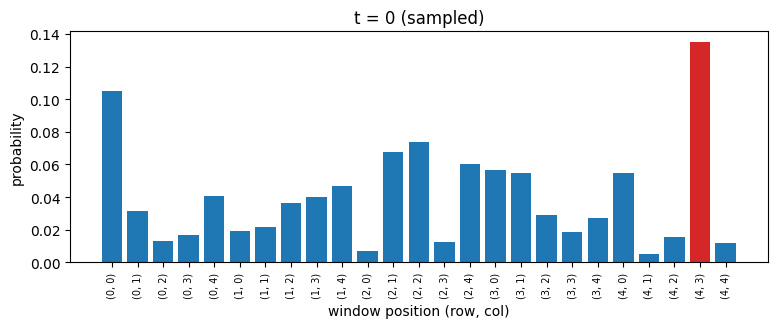

In [5]:
res0 = matcher.run(num_iterations=0, shots=20000, seed=1)
exact0 = shares[0][:db.n_windows]

print(f"post-selection success rate: {res0.success_rate:.3f}   (exact s^2 = {s2:.3f})")
print("max |sampled - exact| per bar: %.3f" % np.abs(res0.index_probabilities[:db.n_windows] - exact0).max())

fig, ax = plt.subplots(figsize=(9, 3))
MatchVisualizer.index_histogram(db, res0.index_probabilities, ax, highlight=waldo_idx, title="t = 0 (sampled)")
plt.show()

## 5. Amplitude amplification
`t*` follows Eq. (18). With so few windows the starting success is already large, so only ~1 iteration is needed. The whole point of Grover is that for a large database `s ≈ 1/√N_I` and `t* ≈ √N_I`. Overshooting makes the success probability oscillate back down.

optimal iterations t* = 1


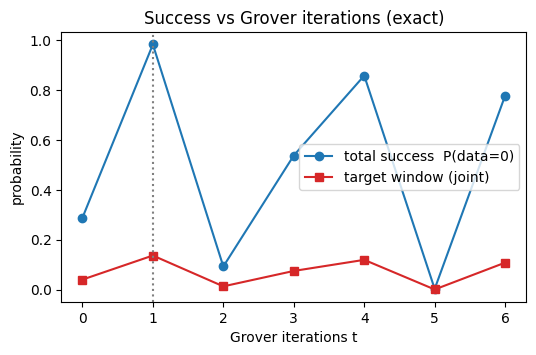

In [6]:
t_star = matcher.optimal_iterations(s2)
print("optimal iterations t* =", t_star)

fig, ax = plt.subplots(figsize=(6, 3.5))
MatchVisualizer.iteration_scan(scan, waldo_idx, ax, title="Success vs Grover iterations (exact)")
ax.axvline(t_star, ls=":", c="gray")
plt.show()

## 6. Final run at `t*`

post-selection success rate: 0.982  (was 0.289 at t=0)
best window position : (4, 3) | true Waldo position: (4, 3)
runner-up            : (0, 0) with share 0.103 vs best 0.141


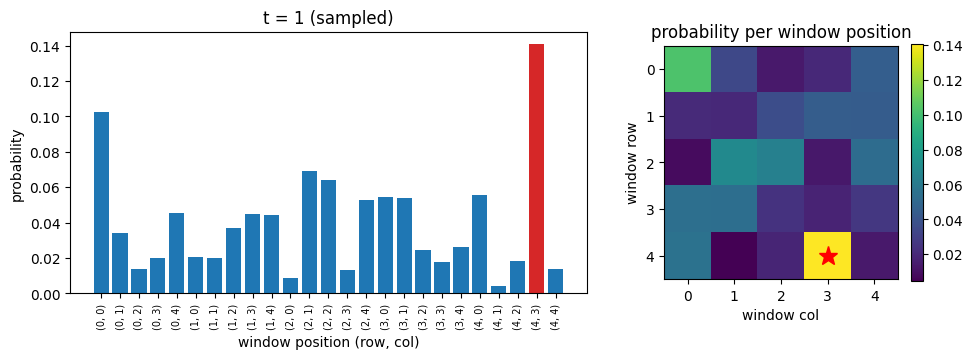

circuit resources (compiled to u + cx): {'qubits': 10, 'depth': 6724, 'cx': 3442, 'single_qubit': 3531}


In [7]:
res = matcher.run(num_iterations=t_star, shots=20000, seed=2)
order = np.argsort(-res.index_probabilities)

print(f"post-selection success rate: {res.success_rate:.3f}  (was {res0.success_rate:.3f} at t=0)")
print("best window position :", db.position_of(res.best_index), "| true Waldo position:", scene.waldo_position)
print("runner-up            :", db.position_of(int(order[1])), "with share %.3f vs best %.3f"
      % (res.index_probabilities[order[1]], res.index_probabilities[order[0]]))
assert res.best_index == waldo_idx

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [2, 1]})
MatchVisualizer.index_histogram(db, res.index_probabilities, ax[0], highlight=waldo_idx, title=f"t = {t_star} (sampled)")
MatchVisualizer.position_heatmap(db, res.index_probabilities, ax[1], title="probability per window position", mark=scene.waldo_position)
plt.show()

print("circuit resources (compiled to u + cx):", matcher.resource_summary(t_star))

## 7. Swap the encoder: NCC (one line changes)
NEQR scores are *fractions of identical pixels*, so noisy windows still get a lot of weight (Waldo's share above is modest). `AmplitudeNCCEncoder` subtracts the mean and normalises, so the overlap becomes the true **normalised cross-correlation**, which separates Waldo much better. (Because probabilities go like NCC², a perfectly *inverted* Waldo would score high too.)

 NEQR: qubits=10 | s^2=0.288 | t*=1 | success=0.984 | best=(4, 3) | Waldo share=0.136 | next best=0.109


  NCC: qubits= 9 | s^2=0.151 | t*=1 | success=0.867 | best=(4, 3) | Waldo share=0.260 | next best=0.163


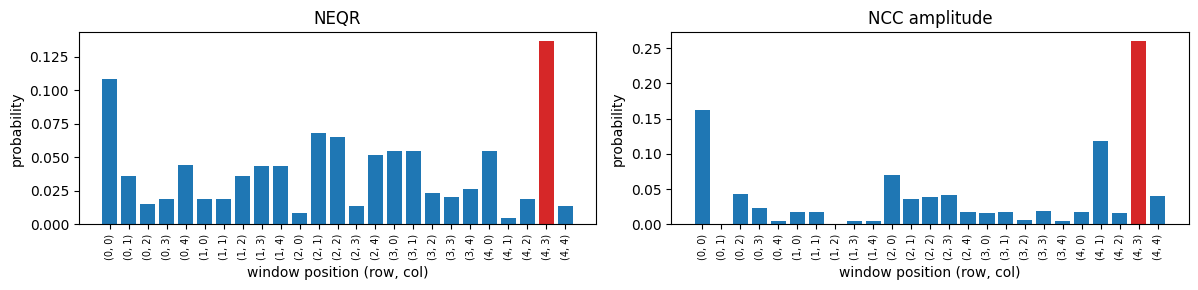

In [8]:
def evaluate(encoder, label):
    db_ = WindowDatabase(scene.image, WindowExtractor((4, 4), stride=1), encoder)
    m = GroverTemplateMatcher(db_, scene.waldo)
    w = db_.positions.index(scene.waldo_position)
    s2_ = m.initial_success_probability()
    t_ = m.optimal_iterations(s2_)
    r = m.run(t_, shots=20000, seed=3)
    p = r.index_probabilities
    print(f"{label:>5}: qubits={m.n:2d} | s^2={s2_:.3f} | t*={t_} | success={r.success_rate:.3f} "
          f"| best={db_.position_of(r.best_index)} | Waldo share={p[w]:.3f} | next best={np.sort(p)[-2]:.3f}")
    return db_, r

db_neqr, r_neqr = evaluate(NEQREncoder((4, 4)), "NEQR")
db_ncc,  r_ncc  = evaluate(AmplitudeNCCEncoder((4, 4)), "NCC")

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
MatchVisualizer.index_histogram(db_neqr, r_neqr.index_probabilities, ax[0], highlight=waldo_idx, title="NEQR")
MatchVisualizer.index_histogram(db_ncc,  r_ncc.index_probabilities,  ax[1], highlight=waldo_idx, title="NCC amplitude")
plt.tight_layout(); plt.show()

## 8. Where to go next
* **Loader:** `ExactStatePrepLoader` uses Qiskit's exponential-depth state preparation. Add an `AAELoader(BaseLoader)` (trained hardware-efficient ansatz + MMD loss from the paper); nothing else changes.
* **Scale:** bigger scenes / windows, stride > 1, grayscale NEQR (`n_color_bits > 1`).
* **Cheaper diffusion:** `G_d` is implemented naively as `U R U†`; the paper points to shallower variants.
* **Noise:** pass a noisy `AerSimulator` (or hardware backend) to `matcher.run(..., backend=...)`.